# Figure 4 — path length and alignment on random targets, with the QFT conditioning

One figure from two caches, with no optimisation run here:

- **(a)** the cumulative parameter-space path length $s_m$ and **(b)** the alignment
  $\cos\vartheta_m$ of each step with the geodesic to the target, both on the 50
  Haar-random 3-qubit targets of `fig4ab_parameter_trajectories_diffs_random.ipynb` at
  $L = 120$ and initial spread $\mu = \pi$, read from its `traj_HAAR3_…` blocks under
  `cache/traj`;
- **(c)** the 5-qubit QFT of `fig4c_qft.ipynb` against the pulse length: the infidelity
  above and the condition number of the least-squares Jacobian $\mathrm{cond}(\mathbf J)$
  below, read from its `qft_n5_L…` blocks under `cache/qft`.

The trajectory blocks store every free-column iterate and the target of each run, so
$s_m$ is a sum of parameter differences and needs nothing else. The alignment is not
stored: it is rebuilt here exactly as the random-targets notebook rebuilds it, from the
model's manifold, as the cosine at $U_m$ between $\mathrm{Log}_{U_m}V$ and
$\mathrm{Log}_{U_m}U_{m+1}$. Both notebooks must have been run first; this one raises
rather than computes if a block is missing.


In [1]:
from common import *

# The Figure 4(a,b) random-targets problem: the block tags are built from these.
L_STEPS = 120
SPREAD_RANDOM = 1.0  # initial spread, in units of pi
SPREAD_LABELS = {0.01: r"\pi/100", 1.0: r"\pi"}

# The Figure 4(c) sweep: one block per pulse length.
L_QFT = [120, 160, 200, 240, 280]

#: How the heavy lines combine the random targets in (a) and (b): "mean", as the
#: random-targets notebook draws them, or "median". Panel (c) is a median over seeds,
#: as its own notebook draws it.
AGGREGATE = "mean"

#: `METHODS` names the optimisers as the legends do, `COLOURS` and `LABELS` as the
#: Figure 3 cache folders do; this maps the one onto the other.
STYLE_KEYS = {
    "GEOPE": "GEOPE",
    "LBFGS": "LBFGS",
    "Newton: TRM": "NewtonTRM",
    "Newton: RFO": "NewtonRFO",
    "Newton: SFN": "NewtonSaddleFree",
}
CACHE = pathlib.Path("cache")


## The saved data

Each block is found by its tag rather than by rebuilding the config hash, so the two
notebooks' constants are not duplicated here; there must be exactly one block per tag.
A trajectory block holds `n_runs` runs of `phi` (the free-column iterates), `fid`, `gs`
and `target`; a QFT block holds `fid_<seed>`, `cond_<seed>` and `rank_<seed>` per seed.


In [2]:
def one_block(pattern):
    """The single cached ``.npz`` matching ``pattern``, or a clear error."""
    matches = sorted(CACHE.glob(pattern))
    if len(matches) != 1:
        raise FileNotFoundError(
            f"{len(matches)} blocks match {pattern}; run the notebook that builds it first"
        )
    return matches[0]


def load_trajectories(method):
    """``[{"phi", "fid", "gs", "target"}, ...]``, run ``i`` on Haar target ``i``."""
    tag = f"traj_HAAR3_L{L_STEPS}_{spread_slug(SPREAD_RANDOM)}_{method}"
    with np.load(one_block(f"traj/{tag}_*.npz")) as h:
        n = int(h["n_runs"])
        return [{k: h[f"{k}_{s}"] for k in ("phi", "fid", "gs", "target")} for s in range(n)]


def load_qft(steps):
    """``(fidelities, conditionings)`` per seed for one pulse length of Figure 4(c)."""
    with np.load(one_block(f"qft/L{steps}/qft_n5_L{steps}_*.npz")) as h:
        n = int(h["totals"].size)
        return [h[f"fid_{s}"] for s in range(n)], [h[f"cond_{s}"] for s in range(n)]


traj = {method: load_trajectories(method) for method in METHODS}
qft = {steps: load_qft(steps) for steps in L_QFT}

n_targets = {len(runs) for runs in traj.values()}
assert len(n_targets) == 1, f"the trajectory blocks disagree on the number of targets: {n_targets}"
N_TARGETS = n_targets.pop()
print(f"fig4ab: {N_TARGETS} Haar-random targets per optimiser at L = {L_STEPS}, spread {SPREAD_RANDOM:g} pi")
for steps, (fids, conds) in qft.items():
    print(f"fig4c: L = {steps:3d}, {len(fids)} seeds, median {np.median([f.size - 1 for f in fids]):.1f} steps")


fig4ab: 50 Haar-random targets per optimiser at L = 120, spread 1 pi
fig4c: L = 120, 10 seeds, median 93.5 steps
fig4c: L = 160, 10 seeds, median 59.5 steps
fig4c: L = 200, 10 seeds, median 49.0 steps
fig4c: L = 240, 10 seeds, median 44.5 steps
fig4c: L = 280, 10 seeds, median 41.5 steps


## The alignment, rebuilt from the stored iterates

What the blocks log is exactly `Parameters.free`, so `manifold.compute_point` on each
stored row is the unitary that iterate implements; the chart depends on the model and not
on the target, so one jitted map serves every target. At each $U_m$, `manifold.log` gives
the tangent to $U_{m+1}$ and the tangent to the target, and $\cos\vartheta_m$ is their
normalised Frobenius inner product. The fidelity of every rebuilt unitary is checked
against the one the optimiser recorded.


In [3]:
def group_geometry(steps, spread, target):
    """The model's manifold, with jitted maps from stored rows to unitaries and tangents."""
    params = make_parameters(3, steps, target, spread=spread)  # any target: the chart is target-free
    Geope(params)  # writes the drift columns, as the trajectory runs did
    manifold = params.manifold
    k_free = int(params.proj_drift_indices.sum())

    @jax.jit
    def unitaries(phi):
        free = jnp.asarray(phi.reshape(phi.shape[0], steps, k_free), dtype=jnp.complex128)
        return jax.vmap(manifold.compute_point)(free)

    @jax.jit
    def fidelities(points, target):
        return jax.vmap(lambda u: manifold.fidelity(u, target))(points)

    @jax.jit
    def alignments(points, target):
        """cos of the angle at U_m between the geodesic to the target and the step taken."""

        def one(u, u_next):
            to_target = manifold.log(u, target)
            taken = manifold.log(u, u_next)
            scale = jnp.linalg.norm(to_target) * jnp.linalg.norm(taken)
            defined = scale > 1e-12  # a step that did not move, or a start on the target
            cosine = jnp.real(jnp.vdot(to_target, taken)) / jnp.where(defined, scale, 1.0)
            return jnp.where(defined, cosine, jnp.nan)

        return jax.vmap(one)(points[:-1], points[1:])

    @jax.jit
    def distance(x, y):
        return jnp.sqrt(2.0 * manifold.distance2(x, y))

    return dict(
        unitaries=unitaries,
        fidelities=fidelities,
        alignments=alignments,
        distance=distance,
        step_distances=jax.jit(lambda points: jax.vmap(distance)(points[:-1], points[1:])),
    )


def path_lengths(run):
    """Cumulative parameter-space path length $s_m$ at every iterate, zero at the start."""
    steps = np.linalg.norm(np.diff(run["phi"], axis=0), axis=1)
    return np.concatenate([[0.0], np.cumsum(steps)])


def group_measures(run, geometry):
    r"""One run's $\cos\vartheta_m$ per step, its cumulative geodesic length $g_m$ and
    $\Vert\Gamma\Vert_g$, the geodesic distance from its start to its target, after
    checking the rebuilt unitaries."""
    target = jnp.asarray(run["target"])
    points = geometry["unitaries"](run["phi"])
    rebuilt = np.asarray(geometry["fidelities"](points, target))
    assert np.abs(rebuilt - run["fid"]).max() < 1e-8, "stored columns do not rebuild the iterate"
    cos = np.asarray(geometry["alignments"](points, target))
    d = np.asarray(geometry["step_distances"](points))
    geo = np.concatenate([[0.0], np.cumsum(d)])
    return cos, geo, float(geometry["distance"](points[0], target))


geometry = group_geometry(L_STEPS, SPREAD_RANDOM, traj["GEOPE"][0]["target"])
lengths = {m: [path_lengths(r) for r in runs] for m, runs in traj.items()}
align, geo_lengths, start_to_target = {}, {}, {}
for m, runs in traj.items():
    measures = [group_measures(r, geometry) for r in runs]
    align[m] = [cos for cos, _geo, _d in measures]
    geo_lengths[m] = [geo for _cos, geo, _d in measures]
    start_to_target[m] = [d for _cos, _geo, d in measures]
print(
    "mean cos vartheta over all steps and targets: "
    + ", ".join(f"{m} {np.nanmean(np.concatenate(align[m])):.2f}" for m in METHODS)
)


mean cos vartheta over all steps and targets: GEOPE 1.00, LBFGS 0.63, Newton: TRM 0.45, Newton: RFO 0.58, Newton: SFN 0.34


## Figure

Left and middle, the random targets: each faint line is one target and the heavy line
the `AGGREGATE` over targets at each iteration. The path length is edge-padded as in
Figure 3, so a run which has converged holds its final length, and its axis is
logarithmic, so iteration 0, where every path is zero, is not drawn. A converged run
takes no further steps, so the alignment is aggregated over the targets still running at
that iteration, and the dotted line at zero separates steps that move towards the target
from steps that move away. Right, the QFT: each faint line is one seed and the heavy line
the median over seeds, in the colour of its pulse length; the dotted line above is the
convergence threshold $1 - F = 10^{-9}$. The optimiser legend runs above the figure, as in
Figure 3, and the pulse-length legend sits in the infidelity panel, as in its own notebook.


figures/fig4_path_alignment_conditioning_L120_spread1pi.pdf


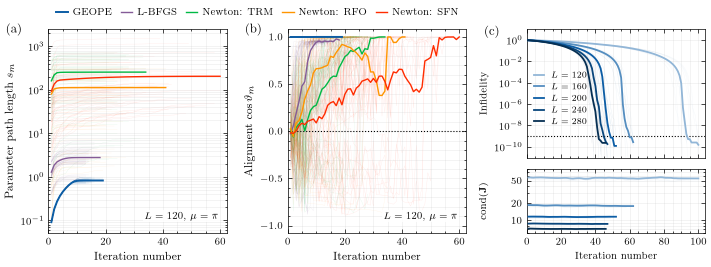

In [4]:
AGGREGATORS = {"mean": (np.mean, np.nanmean), "median": (np.median, np.nanmedian)}


def aggregate_over_runs(curves):
    """Elementwise `AGGREGATE` over runs, edge-padded to the longest as `median_over_runs` is."""
    longest = max(c.size for c in curves)
    padded = np.array([np.pad(c, (0, longest - c.size), mode="edge") for c in curves])
    return AGGREGATORS[AGGREGATE][0](padded, axis=0)


def aggregate_of_running(curves):
    """Elementwise `AGGREGATE` over the runs that still have a value at each index: no padding."""
    longest = max(c.size for c in curves)
    padded = np.full((len(curves), longest), np.nan)
    for row, c in zip(padded, curves):
        row[: c.size] = c
    return AGGREGATORS[AGGREGATE][1](padded, axis=0)


def draw_lengths(ax, curves_by_method):
    """Cumulative length against iteration, the aggregate over faint individual runs, from step 1."""
    for method, curves in curves_by_method.items():
        for y in curves:
            ax.semilogy(np.arange(1, y.size), y[1:], color=COLOURS[STYLE_KEYS[method]], **FAINT)
    for method, curves in curves_by_method.items():
        y = aggregate_over_runs(curves)
        ax.semilogy(np.arange(1, y.size), y[1:], **method_style(STYLE_KEYS[method]))


def draw_alignment(ax, curves_by_method):
    """cos vartheta of step m at iteration m, the aggregate over the targets still running."""
    for method, curves in curves_by_method.items():
        for y in curves:
            ax.plot(np.arange(1, y.size + 1), y, color=COLOURS[STYLE_KEYS[method]], **FAINT)
    for method, curves in curves_by_method.items():
        y = aggregate_of_running(curves)
        ax.plot(np.arange(1, y.size + 1), y, **method_style(STYLE_KEYS[method]))
    ax.axhline(0.0, color="black", ls=":", lw=0.8, zorder=2)
    ax.set_ylim(-1.08, 1.08)
    ax.set_yticks([-1.0, -0.5, 0.0, 0.5, 1.0])


# Panel (c) is GEOPE alone, so its pulse lengths are shades of GEOPE's blue: the base
# colour lightened towards white for the shorter pulses and darkened for the longer.
import matplotlib.colors as mcolors

def shade(colour, amount):
    """``colour`` mixed towards white (``amount`` < 0) or black (``amount`` > 0)."""
    rgb = np.array(mcolors.to_rgb(colour))
    return tuple(rgb + (1 - rgb) * -amount) if amount < 0 else tuple(rgb * (1 - amount))

QFT_COLOURS = dict(zip(L_QFT, [shade(COLOURS["GEOPE"], a) for a in (-0.55, -0.3, 0.0, 0.25, 0.5)]))

fig = plt.figure(figsize=(TWO_COLUMN, 2.5))
grid = fig.add_gridspec(
    2, 3, height_ratios=[2.0, 1.0], hspace=0.12, wspace=0.34,
    left=0.065, right=0.99, top=0.985, bottom=0.17,
)
ax_param = fig.add_subplot(grid[:, 0])
ax_align = fig.add_subplot(grid[:, 1])
ax_fid = fig.add_subplot(grid[0, 2])
ax_cond = fig.add_subplot(grid[1, 2], sharex=ax_fid)

# (a), (b): the random targets.
draw_lengths(ax_param, lengths)
draw_alignment(ax_align, align)
longest = max(r["phi"].shape[0] - 1 for runs in traj.values() for r in runs)
for ax in (ax_param, ax_align):
    ax.set_xlim(0, 1.04 * longest)
    ax.set_xlabel("Iteration number")
    ax.text(
        0.95, 0.07, rf"$L={L_STEPS}$, $\mu={SPREAD_LABELS[SPREAD_RANDOM]}$",
        transform=ax.transAxes, ha="right", fontsize=ANNOTATION_SIZE, zorder=5,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2),
    )
ax_param.set_ylabel(r"Parameter path length $s_m$")
ax_align.set_ylabel(r"Alignment $\cos\vartheta_m$")

# (c): the QFT, infidelity over conditioning, both medians over faint seeds. Its two
# half-height panels take smaller text than (a) and (b).
PANEL_C_SIZE = ANNOTATION_SIZE
for steps, (fids, _conds) in qft.items():
    for y in infidelities(fids):
        ax_fid.semilogy(np.arange(y.size), y, color=QFT_COLOURS[steps], **FAINT)
for steps, (fids, _conds) in qft.items():
    y = median_over_runs(infidelities(fids))
    ax_fid.semilogy(np.arange(y.size), y, color=QFT_COLOURS[steps], lw=1.3, zorder=3, label=rf"$L = {steps}$")
ax_fid.axhline(1.0 - PRECISION, color="black", ls=":", lw=0.8, zorder=2)
ax_fid.set_ylim(1e-11, 10.0)
ax_fid.set_ylabel("Infidelity", fontsize=PANEL_C_SIZE)
ax_fid.legend(loc="lower left", bbox_to_anchor=(0.0, 0.19), fontsize=PANEL_C_SIZE - 1, handlelength=1.2, frameon=False)
ax_fid.tick_params(labelbottom=False)

for steps, (_fids, conds) in qft.items():
    for c in conds:
        ax_cond.semilogy(np.arange(1, c.size), c[1:], color=QFT_COLOURS[steps], **FAINT)
for steps, (_fids, conds) in qft.items():
    y = median_over_runs([c[1:] for c in conds])
    ax_cond.semilogy(np.arange(1, y.size + 1), y, color=QFT_COLOURS[steps], lw=1.3, zorder=3)
ax_cond.set_ylim(6, 80)
ax_cond.set_yticks([10, 20, 50])
ax_cond.set_yticklabels(["10", "20", "50"])
ax_cond.yaxis.set_minor_formatter(NullFormatter())
ax_cond.set_ylabel(r"cond$(\mathbf{J})$", fontsize=PANEL_C_SIZE)
ax_cond.set_xlabel("Iteration number", fontsize=PANEL_C_SIZE)
longest_qft = max(f.size - 1 for fids, _conds in qft.values() for f in fids)
ax_fid.set_xlim(0, 1.04 * longest_qft)
for ax in (ax_fid, ax_cond):
    ax.tick_params(labelsize=PANEL_C_SIZE)
fig.align_ylabels((ax_fid, ax_cond))

for ax in (ax_param, ax_align, ax_fid, ax_cond):
    ax.grid(alpha=0.25, which="both", lw=0.4)

# Panel letters outside the axes and one optimiser legend above, as in Figure 3.
for ax, letter in zip((ax_param, ax_align, ax_fid), "abc"):
    ax.text(
        -0.24, 1.03, rf"({letter})", transform=ax.transAxes, ha="left", va="top",
        fontsize=PANEL_LABEL_SIZE, zorder=5,
    )
# The optimiser legend is centred over (a) and (b) only; (c) has its own.
handles, labels = ax_param.get_legend_handles_labels()
centre = 0.5 * (ax_param.get_position().x0 + ax_align.get_position().x1)
fig.legend(
    handles, labels, loc="lower center", ncol=5, frameon=False,
    bbox_to_anchor=(centre, 1.0), handlelength=1.2, columnspacing=0.9, handletextpad=0.5,
)
print(save_figure(fig, f"fig4_path_alignment_conditioning_L{L_STEPS}_{spread_slug(SPREAD_RANDOM)}"))
plt.show()


## Figure B1 — the cumulative geodesic path length, landscape

The middle panel of the random-targets figure on its own, at one-column width: the
cumulative geodesic distance $g_m$ travelled on $\mathrm{SU}(8)$ after $m$ iterations,
each faint line one target and the heavy line the `AGGREGATE` over targets, edge-padded
as the path length is. The dotted line is the average over runs of
$\Vert\Gamma\Vert_g$, the length of the geodesic from the initial unitary straight to its
target, which no path that reaches the target can undercut.


figures/figB1_geodesic_path_length_landscape_L120_spread1pi.pdf


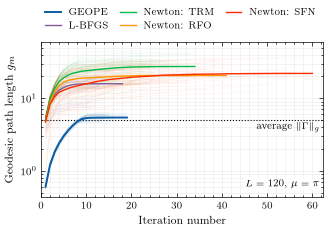

In [5]:
fig, ax_geo = plt.subplots(figsize=(ONE_COLUMN, 2.0))
draw_lengths(ax_geo, geo_lengths)
floor = AGGREGATORS[AGGREGATE][0](np.concatenate([np.asarray(d) for d in start_to_target.values()]))
ax_geo.axhline(floor, color="black", ls=":", lw=0.8, zorder=2)
ax_geo.annotate(
    r"average $\Vert \Gamma \Vert_g$", (0.985, floor), xycoords=("axes fraction", "data"),
    ha="right", va="top", fontsize=ANNOTATION_SIZE, xytext=(0, -1.5), textcoords="offset points",
)
ax_geo.set_xlim(0, 1.04 * longest)
ax_geo.set_xlabel("Iteration number")
ax_geo.set_ylabel(r"Geodesic path length $g_m$")
ax_geo.grid(alpha=0.25, which="both", lw=0.4)
ax_geo.text(
    0.985, 0.07, rf"$L={L_STEPS}$, $\mu={SPREAD_LABELS[SPREAD_RANDOM]}$",
    transform=ax_geo.transAxes, ha="right", fontsize=ANNOTATION_SIZE, zorder=5,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2),
)
handles, labels = ax_geo.get_legend_handles_labels()
fig.legend(
    handles, labels, loc="lower center", ncol=3, frameon=False,
    bbox_to_anchor=(0.56, 1.0), handlelength=1.6, columnspacing=1.2,
)
fig.subplots_adjust(left=0.15, right=0.98, top=0.985, bottom=0.21)
print(save_figure(fig, f"figB1_geodesic_path_length_landscape_L{L_STEPS}_{spread_slug(SPREAD_RANDOM)}"))
plt.show()
